In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
from matplotlib import pyplot as plt

# Q 1

In [4]:
Cars = pd.read_csv('Cars.csv')

In [5]:
Cars.head()

,mpg,cylinders,cubic_inches,horsepower,weight,make_year,time_to_60
0,24.981605,12.0,NaN,236.931297,3864.915410,1986.0,23.530354
1,48.028572,4.0,435.516588,219.690490,4073.256417,1993.0,5.478739
2,39.279758,4.0,263.263790,292.352612,2231.750673,1980.0,8.387293
3,33.946339,6.0,111.026350,144.294317,3395.067908,NaN,18.094014
4,16.240746,4.0,229.451848,135.443933,3935.245398,1992.0,11.531582


In [6]:
Cars.tail()

,mpg,cylinders,cubic_inches,horsepower,weight,make_year,time_to_60
45,36.500891,8.0,NaN,83.661793,2376.616365,NaN,NaN
46,22.468443,4.0,70.223762,NaN,NaN,NaN,6.905415
47,30.802721,12.0,221.604608,189.150207,NaN,1990.0,6.787654
48,31.868411,4.0,201.055941,231.212973,3203.597535,2013.0,24.360274
49,17.394178,3.0,140.802017,343.198537,4671.345757,2017.0,19.006497


In [7]:
Cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           45 non-null     float64
 1   cylinders     45 non-null     float64
 2   cubic_inches  45 non-null     float64
 3   horsepower    45 non-null     float64
 4   weight        45 non-null     float64
 5   make_year     45 non-null     float64
 6   time_to_60    45 non-null     float64
dtypes: float64(7)
memory usage: 2.9 KB


In [8]:
Cars.describe()

,mpg,cylinders,cubic_inches,horsepower,weight,make_year,time_to_60
count,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000
mean,28.215234,6.755556,264.385962,225.382591,3518.545952,1994.844444,13.027810
std,11.732570,3.303962,117.284440,90.354607,968.918738,16.260599,6.354084
min,11.375541,3.000000,70.223762,72.712286,1563.263773,1962.000000,4.108882
25%,17.394178,4.000000,171.473515,144.294317,2578.212771,1986.000000,8.081981
50%,27.277801,6.000000,249.099278,219.690490,3454.027088,1993.000000,10.891206
75%,37.369321,10.000000,356.346613,293.706495,4463.313998,2008.000000,18.112549
max,48.796394,12.000000,487.836201,399.209170,4986.887949,2020.000000,24.618659


# Q4

In [9]:
# 4. Identify columns with missing values
print("\n======= Missing values per column:=======")
print(Cars.isnull().sum())


======= Missing values per column:=======
mpg             5
cylinders       5
cubic_inches    5
horsepower      5
weight          5
make_year       5
time_to_60      5
dtype: int64


In [19]:
Cars.fillna(0, inplace=True)


In [ ]:
# After replacing missing values
print("\n=== MISSING VALUES BEFORE ===")
print(Cars.isna().sum())



=== MISSING VALUES BEFORE ===
mpg             0
cylinders       0
cubic_inches    0
horsepower      0
weight          0
make_year       0
time_to_60      0
dtype: int64


In [23]:
# Check and clean column names
Cars.columns = Cars.columns.str.strip()
print(Cars.columns)

# Select numeric columns for clustering
features = Cars[['mpg', 'cylinders', 'cubic_inches', 'horsepower', 'weight', 'time_to_60']]
print(features.head())

Index(['mpg', 'cylinders', 'cubic_inches', 'horsepower', 'weight', 'make_year',
       'time_to_60'],
      dtype='object')
         mpg  cylinders  cubic_inches  horsepower       weight  time_to_60
0  24.981605       12.0      0.000000  236.931297  3864.915410   23.530354
1  48.028572        4.0    435.516588  219.690490  4073.256417    5.478739
2  39.279758        4.0    263.263790  292.352612  2231.750673    8.387293
3  33.946339        6.0    111.026350  144.294317  3395.067908   18.094014
4  16.240746        4.0    229.451848  135.443933  3935.245398   11.531582


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

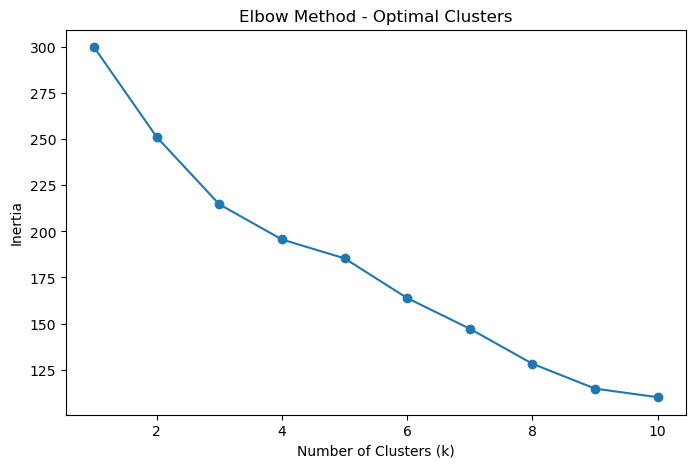

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

# Test k values from 1 to 10
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(scaled_features)
    inertia.append(model.inertia_)

# Plot the Elbow Curve
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(scaled_features)
    inertia.append(model.inertia_)

In [26]:
optimal_k = 3
print("Optimal number of clusters:", optimal_k)

Optimal number of clusters: 3


In [30]:
# Train KMeans with optimal k
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
Cars['Cluster'] = kmeans.fit_predict(scaled_features)

# View dataset with cluster labels
print(Cars.head())

         mpg  cylinders  cubic_inches  horsepower       weight  make_year  \
0  24.981605       12.0      0.000000  236.931297  3864.915410     1986.0   
1  48.028572        4.0    435.516588  219.690490  4073.256417     1993.0   
2  39.279758        4.0    263.263790  292.352612  2231.750673     1980.0   
3  33.946339        6.0    111.026350  144.294317  3395.067908        0.0   
4  16.240746        4.0    229.451848  135.443933  3935.245398     1992.0   

   time_to_60  Cluster  
0   23.530354        0  
1    5.478739        2  
2    8.387293        2  
3   18.094014        0  
4   11.531582        0  


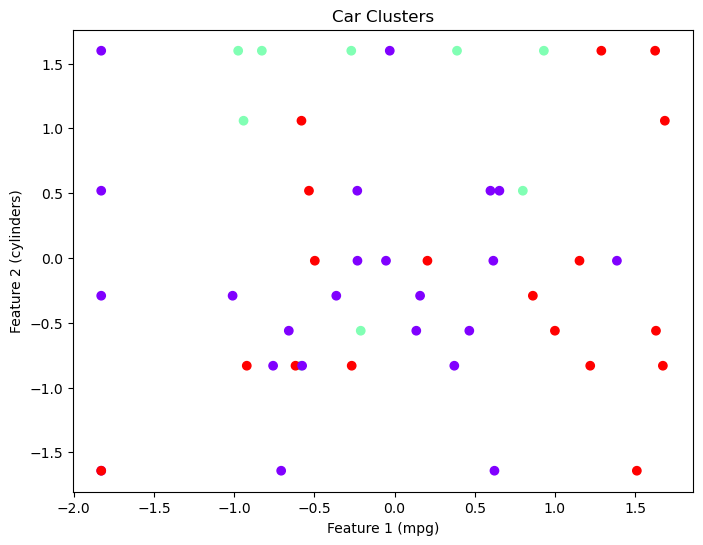

In [32]:
plt.figure(figsize=(8,6))
plt.scatter(scaled_features[:,0], scaled_features[:,1], c=Cars['Cluster'], cmap='rainbow')
plt.title("Car Clusters")
plt.xlabel("Feature 1 (mpg)")
plt.ylabel("Feature 2 (cylinders)")
plt.show()